In [1]:
#Все необходимые библиотеки
import pandas as pd
import os
import numpy as np
import cv2
from PIL import Image
import copy

import torch
import torch.nn as nn
import torch.optim as optim
import torch as th

import torchvision
from torchvision import datasets, models
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

from skimage.io import imread
from torch.utils import data
from tqdm import tqdm

import glob
import re

import time

from sklearn.metrics import confusion_matrix
import seaborn as sns

from torchmetrics.classification import MulticlassSpecificity
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import matthews_corrcoef

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Класс для создания общего датасета с метаданными
class CombineDataset(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, is_aug):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.is_aug = is_aug
        
        if self.is_aug == 1:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.RandomHorizontalFlip(),
                    transforms.RandomRotation(degrees=60),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        else:
            self.aug = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
            
            

    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img_name = self.frame[self.id_col].iloc[idx]
        img = os.path.join (self.path_imgs, img_name +'.jpg')

        image1 = Image.open(img)
        image = self.aug(image1)

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return image, feats, label, name
    
class CombineDataset_cache(Dataset):

    def __init__(self, frame, id_col, label_name, path_imgs, use_cache = False):
        
        self.frame = frame
        self.id_col = id_col
        self.label_name = label_name
        self.path_imgs = path_imgs
        self.inputs_dtype = torch.float32
        
        self.transform = transforms.Compose([
                    transforms.Resize((img_size, img_size)),
                    transforms.ToTensor(),
                    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
                    ])
        
        self.use_cache = use_cache
        
        if self.use_cache:
            self.cached_data = []

            progressbar = tqdm(range(len(self.path_imgs)), desc='Caching')
            
            for i, img in zip(progressbar, self.path_imgs):
                img = Image.open(img)
                img= self.transform(img)                
                self.cached_data.append(img)
            
    def __len__(self):
        return (self.frame.shape[0])

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        
        img = self.cached_data[idx]

        feats = [feat for feat in self.frame.columns if feat not in [self.label_name,self.id_col]]
        feats  = np.array(self.frame[feats].iloc[idx])
        feats = feats.tolist()
        feats = torch.FloatTensor(feats)

        label = np.array(self.frame[self.label_name].iloc[idx])
        label = torch.tensor(label, dtype=torch.long)
        
        name = self.frame[self.id_col].iloc[idx]

        return img, feats, label, name
    
    
    # Определение процессора для обучения 
def get_default_device():
    if torch.cuda.is_available():
        
        return torch.device('cuda')
    else:
        return torch.device('cpu')

In [3]:
#Класс для выведения индексов для разделения базы изображений
class Sampler(object):
    def __init__(self, data_source):
        pass
    
    def __iter__(self):
        raise NotImplementedError
        
    def __len__(self):
        raise NotImplementedError
        
class StratifiedSampler(Sampler):
    
    def __init__(self, class_vector, z):
        self.n_splits = 1
        self.class_vector = class_vector
        self.test_size = z

    def gen_sample_array(self):
        try:
            from sklearn.model_selection import StratifiedShuffleSplit
        except:
             print('Ошибка распределения изображений')
        import numpy as np
        
        s = StratifiedShuffleSplit(n_splits=self.n_splits, test_size=self.test_size)
        X = th.randn(self.class_vector.size(0),2).numpy()
        y = self.class_vector.numpy()
        s.get_n_splits(X, y)

        train_index, test_index= next(s.split(X, y))
        return train_index, test_index

    def __iter__(self):
        return iter(self.gen_sample_array())

    def __len__(self):
        return len(self.class_vector)

In [4]:
data_dir = "C:\\Users\\...\\CLEAN DATASET\\"
metadata = pd.read_csv('C:\\Users\\...\\MetaData2.csv')

numbers = re.compile(r'(\d+)')
def numericalSort(value):
    parts = numbers.split(value)
    parts[1::2] = map(int, parts[1::2])
    return parts

data_dir2 = sorted(glob.glob('C:\\Users\\...\\CLEAN DATASET\\*.jpg'), key=numericalSort)

labels_cat = ['0. vascular lesions', '1. nevus', '2. solar lentigo', '3. dermatofibroma', '4. seborrheic ketarosis', '5. benign ketarosis', '6. actinic keratosis', '7. basal cell carcinoma', '8. squamous cell carcinoma', '9. melanoma']
labels_cat2 = ['vascular lesions', 'nevus', 'solar lentigo', 'dermatofibroma', 'seborrheic ketarosis', 'benign ketarosis', 'actinic keratosis', 'basal cell carcinoma', 'squamous cell carcinoma', 'melanoma']

img_size = 224
num_classes = 10
num_epochs = 10

#CPU или GPU
device = get_default_device()
device

device(type='cuda')

In [5]:
#Кодируем метаданные

metadata_age = metadata[['age']]
Age_grup = []

for i in metadata_age['age']:
    if i <= 44:
        Age_grup += ['young']
        #print('молодой')
    elif 45 <= i <= 59:
        Age_grup += ['middle']
        #print('средний')
    elif 60 <= i <= 74:
        Age_grup += ['elderly']
        #print('пожилой')
    elif 75 <= i:
        Age_grup += ['senile']
        #print('долгожители')
    else:
        Age_grup += ['error']
        #print('ошибка')
        
metadata['age'] = Age_grup

In [6]:
#Кодируем метаданные

encode_map_categor = {'0. vascular lesions': 0, '1. nevus': 1, '2. solar lentigo': 2, '3. dermatofibroma': 3, '4. seborrheic ketarosis': 4, '5. benign ketarosis': 5, '6. actinic keratosis': 6, '7. basal cell carcinoma': 7, '8. squamous cell carcinoma': 8, '9. melanoma': 9}

encode_map_age = {'young': 0, 'middle': 1, 'elderly': 2, 'senile': 3}
encode_map_sex = {'male': 0, 'female': 1}
encode_map_anatomloc = {'anterior torso': 0, 'head/neck': 1, 'lateral torso': 2, 'lower extremity': 3, 'oral/genital': 4, 'palms/soles': 5, 'posterior torso': 6, 'upper extremity': 7}

#encode_map_age = {'young': '0001', 'middle': '0010', 'elderly': '0100', 'senile': '1000'}
#encode_map_sex = {'male': '01', 'female': '10'}
#encode_map_anatomloc = {'anterior torso': '00000001', 'head/neck': '00000010', 'lateral torso': '00000100', 'lower extremity': '00001000', 'oral/genital': '00010000', 'palms/soles': '00100000', 'posterior torso': '01000000', 'upper extremity': '10000000'}

metadata['diagnosis'].replace(encode_map_categor, inplace=True)
metadata['age'].replace(encode_map_age, inplace=True)
metadata['sex'].replace(encode_map_sex, inplace=True)
metadata['anatomloc'].replace(encode_map_anatomloc, inplace=True)

metadata['diagnosis'] = np.array(metadata['diagnosis'], dtype=np.int32)
metadata['age'] = np.array(metadata['age'], dtype=np.int32)
metadata['sex'] = np.array(metadata['sex'], dtype=np.int32)
metadata['anatomloc'] = np.array(metadata['anatomloc'], dtype=np.int32)

C:\Users\Ulyana\AppData\Local\Temp\ipykernel_11740\1033980212.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  metadata['diagnosis'].replace(encode_map_categor, inplace=True)
C:\Users\Ulyana\AppData\Local\Temp\ipykernel_11740\1033980212.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metada

In [7]:
metadata

,name,diagnosis,age,sex,anatomloc
0,ISIC_0010512,6,3,0,1
1,ISIC_0010889,6,0,1,0
2,ISIC_0024468,6,3,0,1
3,ISIC_0024470,6,2,0,7
4,ISIC_0024511,6,1,1,1
...,...,...,...,...,...
41720,ISIC_0072937,0,2,1,3
41721,ISIC_0072964,0,0,0,0
41722,ISIC_0073012,0,2,1,3
41723,ISIC_0073031,0,0,1,3


In [8]:
#Определяем индексы для разделения базы изображений

test_size = 0.2
valid_size = 0.25

data_label = metadata['diagnosis'].to_numpy()

ss = StratifiedSampler(torch.FloatTensor(data_label), test_size)
pre_train_indices, test_indices = ss.gen_sample_array()

train_label = np.delete(data_label, test_indices, None)
ss = StratifiedSampler(torch.FloatTensor(train_label), valid_size)
train_indices, val_indices = ss.gen_sample_array()

indices = {'train': pre_train_indices[train_indices],
           'val': pre_train_indices[val_indices],
           'test': test_indices
           }

train_indices = indices['train']
val_indices = indices['val']
test_indices = indices['test']

#Выводим индексы для разделения базы изображений

print("Размер тренировочной базы:", len(train_indices))
print("Размер валидационной базы:", len(val_indices))
print("Размер тестовой базы:", len(test_indices))

#torch.save(train_indices, 'Parametr\\train_indices3.pt')
#torch.save(val_indices, 'Parametr\\val_indices3.pt')
#torch.save(test_indices, 'Parametr\\test_indices3.pt')

train_indices = torch.load('Parametr\\train_indices7.pt', weights_only=False)
val_indices = torch.load('Parametr\\val_indices7.pt', weights_only=False)
test_indices = torch.load('Parametr\\test_indices7.pt', weights_only=False)

Размер тренировочной базы: 25035
Размер валидационной базы: 8345
Размер тестовой базы: 8345


In [9]:
len_valset = len(val_indices)
len_trainset = len(train_indices)

In [10]:
#Функция для получения веса для каждой категории
def estimate_weights_mfb(label):
    class_weights = np.zeros_like(label, dtype=float)
    counts = np.zeros_like(label)
    for i,l in enumerate(label):
        m = metadata['diagnosis'].value_counts()
        counts[i] = m[i]
    counts = counts.astype(float)
    median_freq = np.median(counts)
    
    for i, label in enumerate(label):
        class_weights[i] = median_freq / counts[i]
    return class_weights

weight = estimate_weights_mfb(labels_cat)
weight = torch.FloatTensor(weight).to(device)

for i in range(len(labels_cat)):
    print(labels_cat[i],":", weight[i])

0. vascular lesions : tensor(3.8893, device='cuda:0')
tensor(0.0353, device='cuda:0')
2. solar lentigo : tensor(3.6444, device='cuda:0')
3. dermatofibroma : tensor(4., device='cuda:0')
4. seborrheic ketarosis : tensor(0.6721, device='cuda:0')
5. benign ketarosis : tensor(0.8954, device='cuda:0')
6. actinic keratosis : tensor(1.1323, device='cuda:0')
7. basal cell carcinoma : tensor(0.2900, device='cuda:0')
8. squamous cell carcinoma : tensor(1.5000, device='cuda:0')
9. melanoma : tensor(0.1758, device='cuda:0')


In [11]:
Data_set = CombineDataset_cache(metadata, 'name', 'diagnosis', data_dir2, use_cache = True)

Caching: 100%|██████████████████████████████████████████████████████████████████| 41725/41725 [02:07<00:00, 326.51it/s]


In [12]:
batch_size = 64

trainloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = train_indices)
valloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = val_indices)
testloader = torch.utils.data.DataLoader(Data_set, batch_size = batch_size, shuffle = False,  sampler = test_indices)

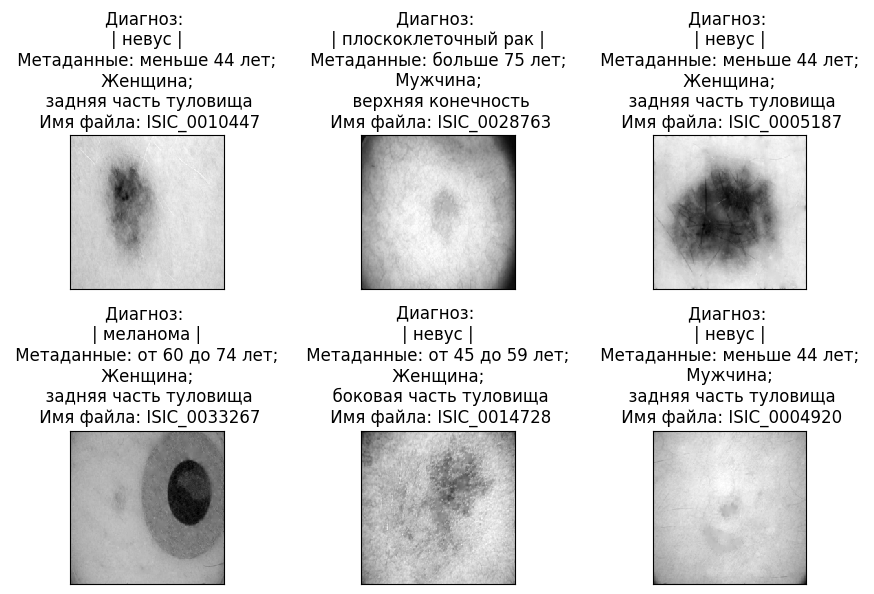

In [13]:
age = ['меньше 44 лет', 'от 45 до 59 лет', 'от 60 до 74 лет', 'больше 75 лет']
sex = ['Мужчина', 'Женщина']
anatomloc = ['торс', 'голова/шея', 'боковая часть туловища', 'нижняя конечность', 'оральная/генитальная зона', 'ладони/подошвы', 'задняя часть туловища', 'верхняя конечность']
lab = ['сосудистое поражение', 'невус', 'солнечное лентиго', 'дерматофиброма', 'себорейный кератоз', 'доброкачественный кератоз', 'актинический кератоз', 'базально-клеточная карцинома', 'плоскоклеточный рак', 'меланома']


examples = enumerate(trainloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

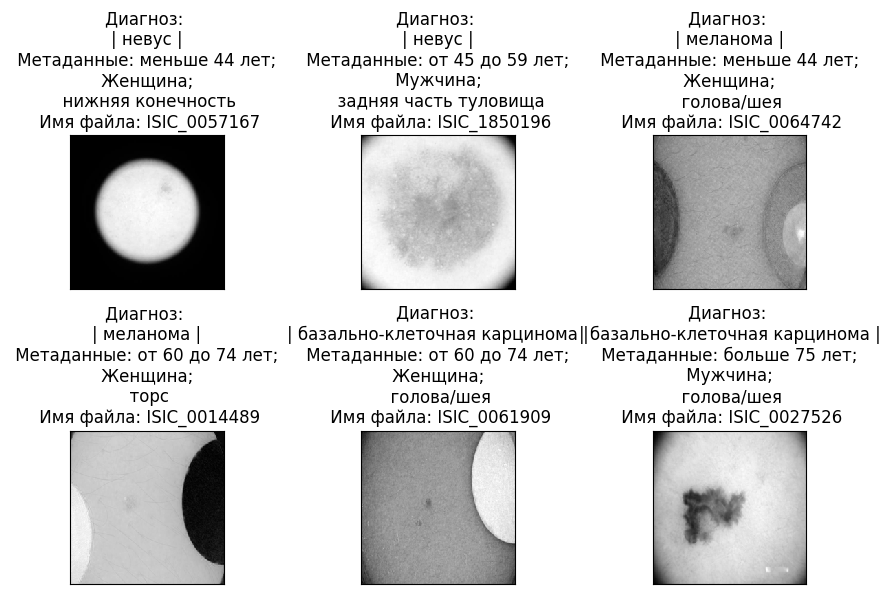

In [14]:
examples = enumerate(valloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

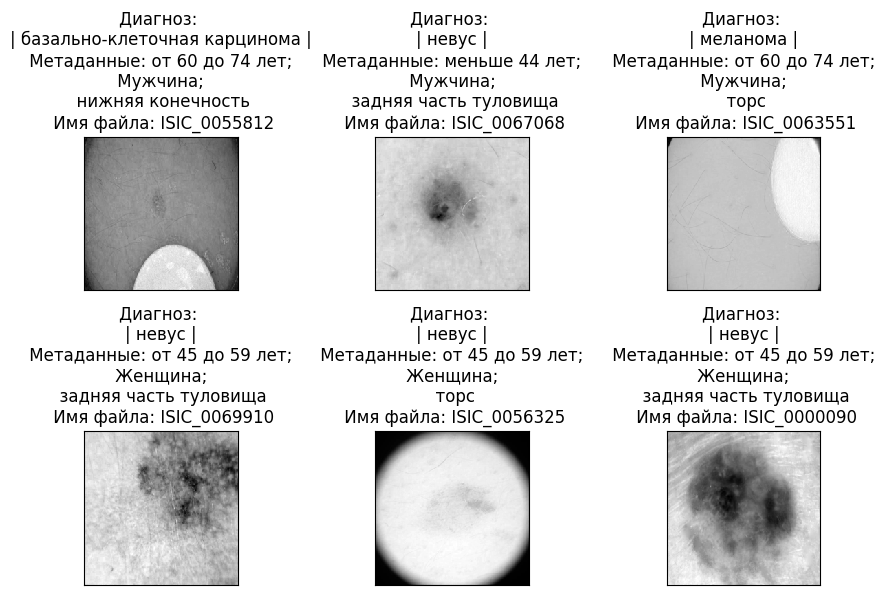

In [15]:
examples = enumerate(testloader)
batch_idx, (example_data, example_meta, example_targets, example_name) = next(examples)

plt.figure(1, figsize=[9,9])
for i in range(6):
    plt.subplot(3, 3, i+1)
    plt.tight_layout()
    plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
    age1 = example_meta[i][0].type(torch.LongTensor)
    sex1 = example_meta[i][1].type(torch.LongTensor)
    anatomloc1 = example_meta[i][2].type(torch.LongTensor)
    plt.title("Диагноз: \n| {} |\n Метаданные: {}; \n {}; \n  {} \n Имя файла: {}".format(lab[example_targets[i]], age[age1], sex[sex1], anatomloc[anatomloc1], example_name[i]))
    plt.xticks([])
    plt.yticks([])

plt.show()

In [16]:
from torchvision.models import resnext101_32x4d, ResNeXt101_32X4D_Weights

ResNeXt_101 = models.resnext101_32x4d(weights=ResNeXt101_32X4D_Weights.IMAGENET1K_V2)

class Classification_M(nn.Module):
    def __init__(self):
        super(Classification_M, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_M = Classification_M()    
    
class MultimodalNN(nn.Module):
    def __init__(self):
        super(MultimodalNN, self).__init__()
        
        self.CNN = resnext50_32x4d
        self.outCNN = nn.Linear(1000, num_classes)
        self.meta_net = Classification_M
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img)
        img = self.outCNN(img)
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x


NET_deep = MultimodalNN()

model_name = 'D:\\Python\\Distillation NN\\ResNeXt_101\\ResNeXt_101-10.pth'
model_weights = torch.load(model_name, device)
NET_deep.load_state_dict(model_weights)
NET_deep = NET_deep.to(device)

NET_deep

MultimodalNN(
  (CNN): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (conv3): Conv2d(128, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): R

In [17]:
class Classification_MM(nn.Module):
    def __init__(self):
        super(Classification_MM, self).__init__()
        
        self.layer_1 = nn.Linear(3, 64)
        self.relu1 = nn.ReLU()
        self.batchnorm1 = nn.BatchNorm1d(64)
        
        self.layer_2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.batchnorm2 = nn.BatchNorm1d(32)
        
        self.layer_out = nn.Linear(32, num_classes) 
        
        
    def forward(self, inputs):
        x = self.layer_1(inputs)
        x = self.relu1(x)
        x = self.batchnorm1(x)
        
        x = self.layer_2(x)
        x = self.relu2(x)
        x = self.batchnorm2(x)
        
        x = self.layer_out(x)
        
        return x

Classification_MM = Classification_MM()

class Net(nn.Module):

   def __init__(self):
      super(Net, self).__init__()
      self.layer1 = nn.Sequential(
         nn.Conv2d(3, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(64, 64, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.layer2 = nn.Sequential(
         nn.Conv2d(64, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.Conv2d(128, 128, kernel_size = (3,3), stride = (1,1), 
         padding = (1,1)),
         nn.ReLU(inplace=True),
         nn.MaxPool2d(kernel_size=2, stride=2, padding=0, 
         dilation=1, ceil_mode=False)
      )
      self.pool1 = nn.AdaptiveAvgPool2d(output_size=(1,1))
      self.fc1 = nn.Linear(128, 32)
      self.fc2 = nn.Linear(32, num_classes)
      self.dropout_rate = 0.5
   
   def forward(self, x):
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.pool1(x)
      x = x.view(x.size(0), -1)
      x = self.fc1(x)
      x = self.fc2(x)
       
      return x
       
LightNN = Net()
    
class MultimodalNN_light(nn.Module):
    def __init__(self):
        super(MultimodalNN_light, self).__init__()
        
        self.CNN = LightNN
       
        self.meta_net = Classification_MM
        
        self.out = nn.Linear(num_classes+num_classes, num_classes)
                
    def forward(self, img , tab):
        
        img = self.CNN(img) 
        img = img.reshape(img.shape[0], -1)
        
        tab = self.meta_net(tab)
        
        x = torch.cat((img, tab),1)
        x = self.out(x)
        
        return x

In [24]:
def test(model, dataset, device):

    start_time_glob = time.time()
    model.to(device)
    model.eval()

    correct = 0
    total = 0
    time_outputs2 = 0

    with torch.no_grad():
        for i, data in enumerate(dataset):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            start_time_outputs = time.time()

            outputs = model(inputs, feats)

            time_outputs = time.time()-start_time_outputs
            time_outputs2 += time_outputs

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    print('_' * 60)
    print ('       Время выхода с сети: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_outputs2))))
    print ('       Время выхода с сети в секундах: {:.6f}'.format(time_outputs2))

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
    
    return accuracy

def test_NN(model, dataset):

    start_time_glob = time.time()
    model.eval()
    
    with torch.no_grad():
        for data in dataset:
            image, feats, label, name = data
            image, feats, label = image.to(device), feats.to(device), label.to(device)

            output = model(image, feats)

            pred = (torch.max(torch.exp(output), 1)[1]).cpu().data.numpy()

            predictions.extend(pred)

            label = label.cpu().data.numpy()
            actuals.extend(label)

    time_glob = time.time()-start_time_glob
    print('_' * 60)
    print ('Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    print ('Время тестирования в секундах: {:.6f}\n'.format(time_glob))
        
def test_metric():
    
    cm = confusion_matrix(actuals, predictions)
    FP = np.mean(cm.sum(axis=0) - np.diag(cm))  
    FN = np.mean(cm.sum(axis=1) - np.diag(cm))
    TP = np.mean(np.diag(cm))
    TN = np.mean(cm.sum() - (FP + FN + TP))

    Sensitivity = (TP/(TP+FN))
    Specificity = (TN/(TN+FP))
    Precision = (TP/(TP+FP))
    NPV = (TN/(TN+FN))
    PPV = (TP/(TP+FP))
    FNR = (FN/(FN+TP))
    FPR = (FP/(FP+TN))

    F1 = (2*TP)/((2*TP)+FP+FN) 

    recall_1 = recall_score(actuals, predictions, average='micro')
    recall_2 = recall_score(actuals, predictions, average='macro')
    

    precision_1 = precision_score(actuals, predictions, average='micro')
    precision_2 = precision_score(actuals, predictions, average='macro')


    f1_1 = f1_score(actuals, predictions, average='micro')
    f1_2 = f1_score(actuals, predictions, average='macro')
    
    jaccard_1 = jaccard_score(actuals, predictions, average='micro')
    jaccard_2 = jaccard_score(actuals, predictions, average='macro')

    accuracy_1 = accuracy_score(actuals, predictions)

    MCC = matthews_corrcoef(actuals, predictions)

    pre = torch.tensor(predictions)
    ac = torch.tensor(actuals)

    specificity1 = MulticlassSpecificity(average='macro', num_classes=10)
    s1 = specificity1(pre, ac)

    specificity2 = MulticlassSpecificity(average='micro', num_classes=10)
    s2 = specificity2(pre, ac)

    specificity3 = MulticlassSpecificity(average='weighted', num_classes=10)
    s3 = specificity3(pre, ac)

    specificity4 = MulticlassSpecificity(average='none', num_classes=10)
    s4 = specificity4(pre, ac)
    
    print('_' * 60)
    print('Accuracy score: %.2f' % (accuracy_1*100))
    print('Sensitivity: %.4f' % Sensitivity)
    print('Specificity: %.4f' % Specificity)
    print('F1: %.4f' % F1)
    print('Matthews corrcoef: %.4f' % MCC)
    print('NPV: %.4f' % NPV)
    print('PPV: %.4f' % PPV)
    print('FNR: %.4f' % FNR)
    print('FPR: %.4f' % FPR)
    
    print('_' * 60)
    print('Recall micro: %.4f' % recall_1)
    print('Recall macro: %.4f' % recall_2)
    print('Precision micro: %.4f' % precision_1)
    print('Precision macro: %.4f' % precision_2)
    print('F1 score micro: %.4f' % f1_1)
    print('F1 score macro: %.4f' % f1_2)
    
    print('Jaccard score micro: %.4f' % jaccard_1)
    print('Jaccard score macro: %.4f' % jaccard_2)
    print('Specificity macro: %.4f' % s1)
    print('Specificity weighted: %.4f' % s3)
    
    print('Specificity none - class vascular lesions (0): %.4f' % s4[0])
    print('Specificity none - class nevus (1): %.4f' % s4[1])
    print('Specificity none - class solar lentigo (2): %.4f' % s4[2])
    print('Specificity none - class dermatofibroma (3): %.4f' % s4[3])
    print('Specificity none - class seborrheic ketarosis (4): %.4f' % s4[4])
    print('Specificity none - class benign ketarosis (5): %.4f' % s4[5])
    print('Specificity none - class actinic keratosis (6): %.4f' % s4[6])
    print('Specificity none - class basal cell carcinoma (7): %.4f' % s4[7])
    print('Specificity none - class squamous cell carcinoma (8): %.4f' % s4[8])
    print('Specificity none - class melanoma (9): %.4f' % s4[9])

In [26]:
import torch.nn.functional as F
import torch
import copy
import time

def train_kd_v2(model, teacher_out, optimizer, loss_fn, dataloader, **loss_kwargs):
    """Универсальная функция обучения с произвольной функцией потерь."""
    model.train()
    start_time_train = time.time()
    running_loss = 0.0
    running_corrects = 0

    for i, data in enumerate(dataloader):
        inputs, feats, labels, name = data
        inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)
        optimizer.zero_grad()

        outputs = model(inputs, feats)
        outputs_teacher = torch.from_numpy(teacher_out[i]).float().to(device)

        loss = loss_fn(outputs, labels, outputs_teacher, **loss_kwargs)
        _, preds = torch.max(outputs, 1)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len_trainset
    epoch_acc = running_corrects.double() / len_trainset
    time_train = time.time() - start_time_train
    print(' Тренировочная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print(' Время обучения: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_train))))


def eval_kd_v2(model, teacher_out, optimizer, loss_fn, dataloader, **loss_kwargs):
    """Универсальная функция валидации."""
    model.eval()
    start_time_test = time.time()
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, data in enumerate(dataloader):
            inputs, feats, labels, name = data
            inputs, feats, labels = inputs.to(device), feats.to(device), labels.to(device)

            outputs = model(inputs, feats)
            outputs_teacher = torch.from_numpy(teacher_out[i]).float().to(device)

            loss = loss_fn(outputs, labels, outputs_teacher, **loss_kwargs)
            _, preds = torch.max(outputs, 1)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

    epoch_loss = running_loss / len_valset
    epoch_acc = running_corrects.double() / len_valset
    time_test = time.time() - start_time_test
    print(' Валидационная ошибка: {:.4f} Точность: {:.4f}'.format(epoch_loss, epoch_acc))
    print(' Время тестирования: {}'.format(time.strftime("%H:%M:%S", time.gmtime(time_test))))
    return epoch_acc


def train_and_evaluate_kd_v2(model, teacher_model, optimizer, loss_fn,
                              trainloader, valloader, num_epochs=20, **loss_kwargs):
    """Универсальная обёртка: предвычисление логитов учителя + цикл обучения."""
    teacher_model.eval()
    start_time_glob = time.time()
    start_time_teacher = time.time()

    print('Процесс вывода весов с архитектуры-учителя...')
    outputs_teacher_train = get_outputs(teacher_model, trainloader)
    outputs_teacher_val = get_outputs(teacher_model, valloader)

    time_teacher = time.time() - start_time_teacher
    print('Время вывода весов с архитектуры-учителя: {}'.format(
        time.strftime("%H:%M:%S", time.gmtime(time_teacher))))

    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(num_epochs):
        print('_' * 60)
        print('Эпоха {}/{}'.format(epoch + 1, num_epochs))

        train_kd_v2(model, outputs_teacher_train, optimizer, loss_fn,
                    trainloader, **loss_kwargs)
        epoch_acc_val = eval_kd_v2(model, outputs_teacher_val, optimizer, loss_fn,
                                   valloader, **loss_kwargs)

        if epoch_acc_val > best_acc:
            best_acc = epoch_acc_val
            best_model_wts = copy.deepcopy(model.state_dict())

        print('\nЛучшая валидационная точность: {:.4f}'.format(best_acc))

    model.load_state_dict(best_model_wts)
    time_glob = time.time() - start_time_glob
    print('_' * 60)
    print('Общее время обучения: {}'.format(
        time.strftime("%H:%M:%S", time.gmtime(time_glob))))
    return model

In [27]:
def loss_kd(outputs, labels, teacher_outputs, temparature, alpha):
    
    KD_loss = nn.KLDivLoss(reduction='batchmean')(F.log_softmax(outputs/temparature, dim=1), F.softmax(teacher_outputs/temparature,dim=1)) * (alpha * temparature * temparature) + F.cross_entropy(outputs, labels) * (1. - alpha)
    
    return KD_loss

def get_outputs(model, dataloader):
    outputs = []
    
    for inputs, feats, labels, name in dataloader:
        inputs_batch, feats_batch, labels_batch = inputs.cuda(), feats.cuda(), labels.cuda()
        output_batch = model(inputs_batch, feats_batch).data.cpu().numpy()
        outputs.append(output_batch)
       
    return outputs

In [28]:
def loss_dkd(outputs, labels, teacher_outputs, alpha=1.0, beta=8.0, temperature=1.0):
    """
    Decoupled Knowledge Distillation (CVPR 2022).
    
    Параметры:
        outputs: логиты ученика [B, C]
        labels: истинные метки [B]
        teacher_outputs: логиты учителя [B, C]
        alpha: вес TCKD (рекомендуется 1.0)
        beta: вес NCKD (рекомендуется 8.0, диапазон [1, 16])
        temperature: температура (обычно 1.0 для DKD)
    """
    B, C = outputs.shape
    
    # Вероятности с температурой
    p_s = F.softmax(outputs / temperature, dim=1)      # [B, C]
    p_t = F.softmax(teacher_outputs / temperature, dim=1)  # [B, C]
    
    # === TCKD: бинарная KL для целевого класса ===
    # Вероятности целевого класса
    p_s_target = p_s[torch.arange(B, device=outputs.device), labels]  # [B]
    p_t_target = p_t[torch.arange(B, device=outputs.device), labels]  # [B]
    
    # Бинарные распределения [p, 1-p]
    s_binary = torch.stack([p_s_target, 1.0 - p_s_target], dim=1)  # [B, 2]
    t_binary = torch.stack([p_t_target, 1.0 - p_t_target], dim=1)  # [B, 2]
    
    tckd = F.kl_div(
        torch.log(s_binary + 1e-7), t_binary, reduction='batchmean'
    )
    
    # === NCKD: KL для нецелевых классов ===
    # Маска нецелевых классов
    mask = torch.ones(B, C, dtype=torch.bool, device=outputs.device)
    mask[torch.arange(B, device=outputs.device), labels] = False
    
    # Извлекаем нецелевые вероятности
    s_non_target = p_s[mask].view(B, C - 1)  # [B, C-1]
    t_non_target = p_t[mask].view(B, C - 1)  # [B, C-1]
    
    # Перенормировка по нецелевым классам
    s_non_target = s_non_target / (s_non_target.sum(dim=1, keepdim=True) + 1e-7)
    t_non_target = t_non_target / (t_non_target.sum(dim=1, keepdim=True) + 1e-7)
    
    nckd = F.kl_div(
        torch.log(s_non_target + 1e-7), t_non_target, reduction='batchmean'
    )
    
    # === Итоговая функция потерь ===
    ce_loss = F.cross_entropy(outputs, labels)
    total = ce_loss + alpha * tckd + beta * nckd
    
    return total

In [29]:
# Эксперимент DKD-1: стандартные гиперпараметры из статьи
torch.manual_seed(42)
LightNN = Net()
student_dkd = MultimodalNN_light().to(device)
optimizer_dkd = torch.optim.SGD(student_dkd.parameters(), lr=0.001, momentum=0.9)

model_dkd = train_and_evaluate_kd_v2(
    student_dkd, NET_deep, optimizer_dkd, loss_dkd,
    trainloader, valloader,
    num_epochs=20,
    alpha=1.0, beta=8.0, temperature=1.0
)

torch.save(model_dkd.state_dict(), "model_dkd\\model_dkd_student.pth")

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:40
____________________________________________________________
Эпоха 1/20
 Тренировочная ошибка: 7.2053 Точность: 0.6561
 Время обучения: 00:00:55
 Валидационная ошибка: 4.8995 Точность: 0.7321
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.7321
____________________________________________________________
Эпоха 2/20
 Тренировочная ошибка: 4.6635 Точность: 0.7470
 Время обучения: 00:00:55
 Валидационная ошибка: 4.4263 Точность: 0.7549
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.7549
____________________________________________________________
Эпоха 3/20
 Тренировочная ошибка: 4.2000 Точность: 0.7629
 Время обучения: 00:00:55
 Валидационная ошибка: 4.0023 Точность: 0.7684
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.7684
____________________________________________________________
Эпоха 4/20
 Тренировочная ошибка: 3.9704 Точность: 0.7674
 

____________________________________________________________
Время тестирования: 00:00:08
Время тестирования в секундах: 8.293443



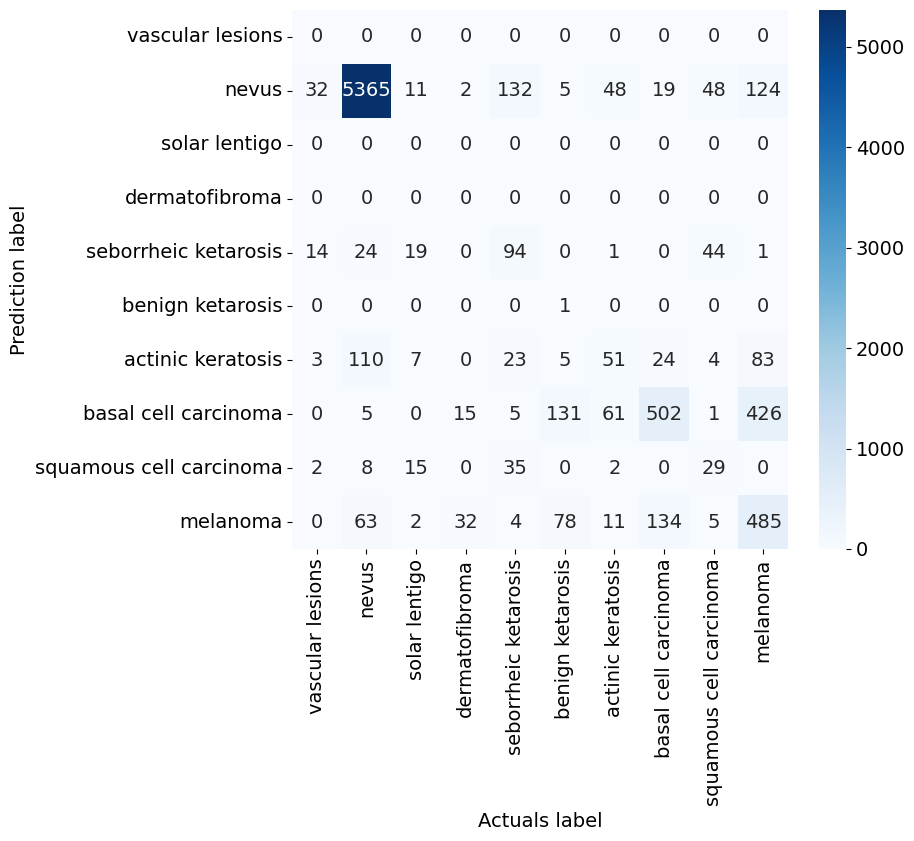

____________________________________________________________
Accuracy score: 78.21
Sensitivity: 0.7821
Specificity: 0.9758
F1: 0.7821
Matthews corrcoef: 0.5774
NPV: 0.9758
PPV: 0.7821
FNR: 0.2179
FPR: 0.0242
____________________________________________________________
Recall micro: 0.7821
Recall macro: 0.2975
Precision micro: 0.7821
Precision macro: 0.3921
F1 score micro: 0.7821
F1 score macro: 0.2861
Jaccard score micro: 0.6422
Jaccard score macro: 0.2119
Specificity macro: 0.9666
Specificity weighted: 0.8843
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8480
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9872
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9683
Specificity none - class basal cell carcinoma (7): 0.9160
Specificity none - class squamous cell carcinoma (8): 0.992

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [31]:
actuals = []
predictions = []

test_NN(model_dkd, testloader)

torch.save(actuals, 'model_dkd\\1actuals.pt')
torch.save(predictions, 'model_dkd\\1predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'model_dkd\\1matrix.pt')

test_metric()

In [32]:
def loss_dist(outputs, labels, teacher_outputs, beta=1.0, temperature=1.0):
    """
    DIST: Knowledge Distillation from A Stronger Teacher (NeurIPS 2022).
    Корреляционная дистилляция на основе межвыборочного сходства.
    
    Параметры:
        outputs: логиты ученика [B, C]
        labels: истинные метки [B]
        teacher_outputs: логиты учителя [B, C]
        beta: вес DIST-потери (диапазон [0.5, 4.0])
        temperature: температура для смягчения распределений
    """
    # Смягчённые логиты
    z_s = outputs / temperature        # [B, C]
    z_t = teacher_outputs / temperature  # [B, C]
    
    # L2-нормализация для вычисления косинусного сходства
    z_s_norm = F.normalize(z_s, p=2, dim=1)  # [B, C]
    z_t_norm = F.normalize(z_t, p=2, dim=1)  # [B, C]
    
    # Матрицы попарного косинусного сходства [B, B]
    S_s = torch.mm(z_s_norm, z_s_norm.t())  # ученик
    S_t = torch.mm(z_t_norm, z_t_norm.t())  # учитель
    
    # Потеря: корреляция Пирсона между матрицами сходств
    # (более устойчива к масштабу, чем MSE)
    S_s_flat = S_s.view(-1)
    S_t_flat = S_t.view(-1)
    
    S_s_centered = S_s_flat - S_s_flat.mean()
    S_t_centered = S_t_flat - S_t_flat.mean()
    
    pearson = (S_s_centered * S_t_centered).sum() / (
        S_s_centered.norm() * S_t_centered.norm() + 1e-8
    )
    
    dist_loss = 1.0 - pearson  # минимизируем 1 - корреляцию
    
    # Стандартная CE-потеря
    ce_loss = F.cross_entropy(outputs, labels)
    
    total = ce_loss + beta * dist_loss
    return total

In [33]:
torch.manual_seed(42)
LightNN = Net()
student_dist = MultimodalNN_light().to(device)
optimizer_dist = torch.optim.SGD(student_dist.parameters(), lr=0.001, momentum=0.9)

model_dist = train_and_evaluate_kd_v2(
    student_dist, NET_deep, optimizer_dist, loss_dist,
    trainloader, valloader,
    num_epochs=20,
    beta=1.0, temperature=1.0
)
torch.save(model_dist.state_dict(), "model_dist\\model_dist.pth")

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:39
____________________________________________________________
Эпоха 1/20
 Тренировочная ошибка: 1.7704 Точность: 0.6558
 Время обучения: 00:00:55
 Валидационная ошибка: 1.5720 Точность: 0.6954
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.6954
____________________________________________________________
Эпоха 2/20
 Тренировочная ошибка: 1.4986 Точность: 0.6936
 Время обучения: 00:00:55
 Валидационная ошибка: 1.2814 Точность: 0.7232
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.7232
____________________________________________________________
Эпоха 3/20
 Тренировочная ошибка: 1.1321 Точность: 0.7436
 Время обучения: 00:00:55
 Валидационная ошибка: 1.0233 Точность: 0.7565
 Время тестирования: 00:00:07

Лучшая валидационная точность: 0.7565
____________________________________________________________
Эпоха 4/20
 Тренировочная ошибка: 0.9889 Точность: 0.7605
 

____________________________________________________________
Время тестирования: 00:00:08
Время тестирования в секундах: 8.271651



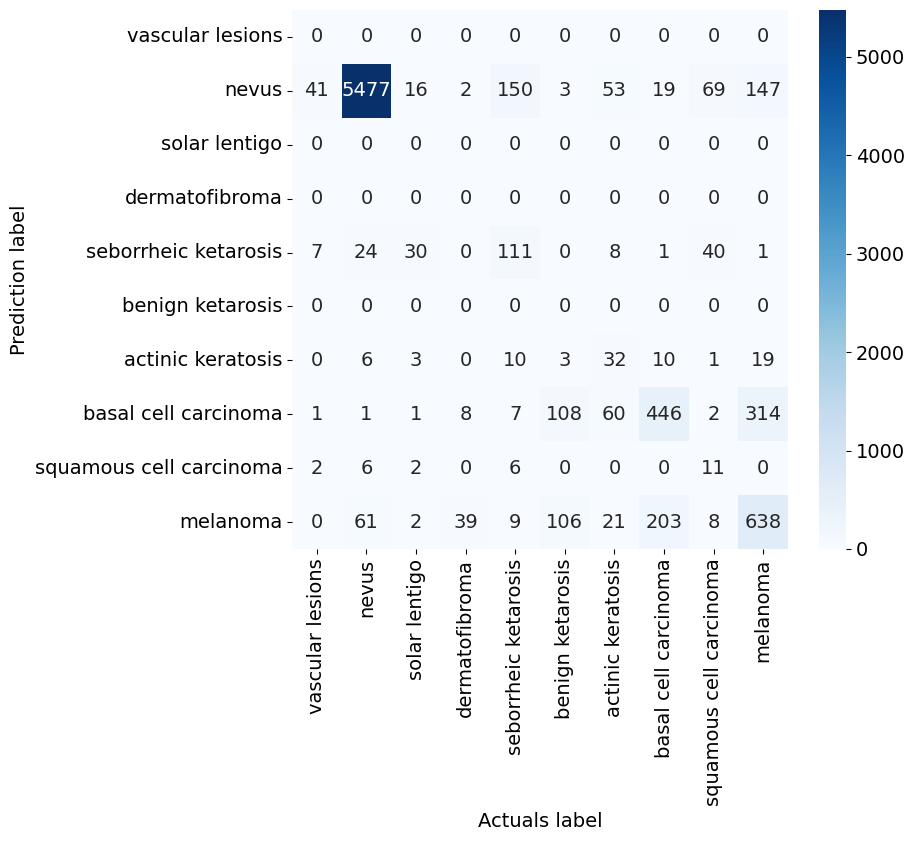

____________________________________________________________
Accuracy score: 80.47
Sensitivity: 0.8047
Specificity: 0.9783
F1: 0.8047
Matthews corrcoef: 0.6086
NPV: 0.9783
PPV: 0.8047
FNR: 0.1953
FPR: 0.0217
____________________________________________________________
Recall micro: 0.8047
Recall macro: 0.2856
Precision micro: 0.8047
Precision macro: 0.3262
F1 score micro: 0.8047
F1 score macro: 0.2893
Jaccard score micro: 0.6732
Jaccard score macro: 0.2177
Specificity macro: 0.9670
Specificity weighted: 0.8651
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8195
Specificity none - class solar lentigo (2): 1.0000
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9862
Specificity none - class benign ketarosis (5): 1.0000
Specificity none - class actinic keratosis (6): 0.9936
Specificity none - class basal cell carcinoma (7): 0.9345
Specificity none - class squamous cell carcinoma (8): 0.998

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [35]:
actuals = []
predictions = []

test_NN(student_dist, testloader)

torch.save(actuals, 'model_dist\\1actuals.pt')
torch.save(predictions, 'model_dist\\1predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'model_dist\\1matrix.pt')

test_metric()

In [36]:
def loss_rkd(outputs, labels, teacher_outputs, 
             distance_weight=25.0, angle_weight=50.0,
             num_triplets=1024):
    """
    Relational Knowledge Distillation (CVPR 2019).
    
    Параметры:
        outputs: логиты ученика [B, C]
        labels: истинные метки [B]
        teacher_outputs: логиты учителя [B, C]
        distance_weight: вес distance-wise потери (из статьи: 25)
        angle_weight: вес angle-wise потери (из статьи: 50)
        num_triplets: число случайных троек для angle-wise
    """
    B, C = outputs.shape
    
    # L2-нормализация логитов (как в оригинальной статье)
    s = F.normalize(outputs, p=2, dim=1)        # [B, C]
    t = F.normalize(teacher_outputs, p=2, dim=1)  # [B, C]
    
    # === Distance-wise loss ===
    # Учитель (без градиентов)
    with torch.no_grad():
        t_dist = torch.cdist(t, t, p=2)  # [B, B]
        mean_td = t_dist[t_dist > 0].mean()
        t_dist = t_dist / (mean_td + 1e-8)
    
    # Ученик
    s_dist = torch.cdist(s, s, p=2)  # [B, B]
    mean_sd = s_dist[s_dist > 0].mean()
    s_dist = s_dist / (mean_sd + 1e-8)
    
    distance_loss = F.smooth_l1_loss(s_dist, t_dist)
    
    # === Angle-wise loss ===
    # Случайные тройки (i, j, k): угол между (e_i - e_j) и (e_k - e_j)
    idx_i = torch.randint(0, B, (num_triplets,), device=outputs.device)
    idx_j = torch.randint(0, B, (num_triplets,), device=outputs.device)
    idx_k = torch.randint(0, B, (num_triplets,), device=outputs.device)
    
    # Векторы разностей для ученика
    v1_s = s[idx_i] - s[idx_j]  # [T, C]
    v2_s = s[idx_k] - s[idx_j]  # [T, C]
    
    # Векторы разностей для учителя (без градиентов)
    with torch.no_grad():
        v1_t = t[idx_i] - t[idx_j]
        v2_t = t[idx_k] - t[idx_j]
    
    # Косинус угла
    cos_s = F.cosine_similarity(v1_s, v2_s, dim=1)  # [T]
    cos_t = F.cosine_similarity(v1_t, v2_t, dim=1)  # [T]
    
    angle_loss = F.smooth_l1_loss(cos_s, cos_t)
    
    # === Итоговая функция потерь ===
    ce_loss = F.cross_entropy(outputs, labels)
    total = ce_loss + distance_weight * distance_loss + angle_weight * angle_loss
    
    return total

In [37]:
torch.manual_seed(42)
LightNN = Net()
student_rkd = MultimodalNN_light().to(device)
optimizer_rkd = torch.optim.SGD(student_rkd.parameters(), lr=0.001, momentum=0.9)

model_rkd = train_and_evaluate_kd_v2(
    student_rkd, NET_deep, optimizer_rkd, loss_rkd,
    trainloader, valloader,
    num_epochs=20,
    distance_weight=25.0, angle_weight=50.0, num_triplets=1024
)

torch.save(model_rkd.state_dict(), "model_rkd\\model_rkd.pth")

Процесс вывода весов с архитектуры-учителя...
Время вывода весов с архитектуры-учителя: 00:00:39
____________________________________________________________
Эпоха 1/20
 Тренировочная ошибка: 9.2205 Точность: 0.7041
 Время обучения: 00:00:56
 Валидационная ошибка: 7.0063 Точность: 0.7613
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.7613
____________________________________________________________
Эпоха 2/20
 Тренировочная ошибка: 6.6166 Точность: 0.7679
 Время обучения: 00:00:55
 Валидационная ошибка: 6.3431 Точность: 0.7745
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.7745
____________________________________________________________
Эпоха 3/20
 Тренировочная ошибка: 6.1158 Точность: 0.7745
 Время обучения: 00:00:55
 Валидационная ошибка: 5.9655 Точность: 0.7812
 Время тестирования: 00:00:08

Лучшая валидационная точность: 0.7812
____________________________________________________________
Эпоха 4/20
 Тренировочная ошибка: 5.9060 Точность: 0.7794
 

____________________________________________________________
Время тестирования: 00:00:08
Время тестирования в секундах: 8.198583



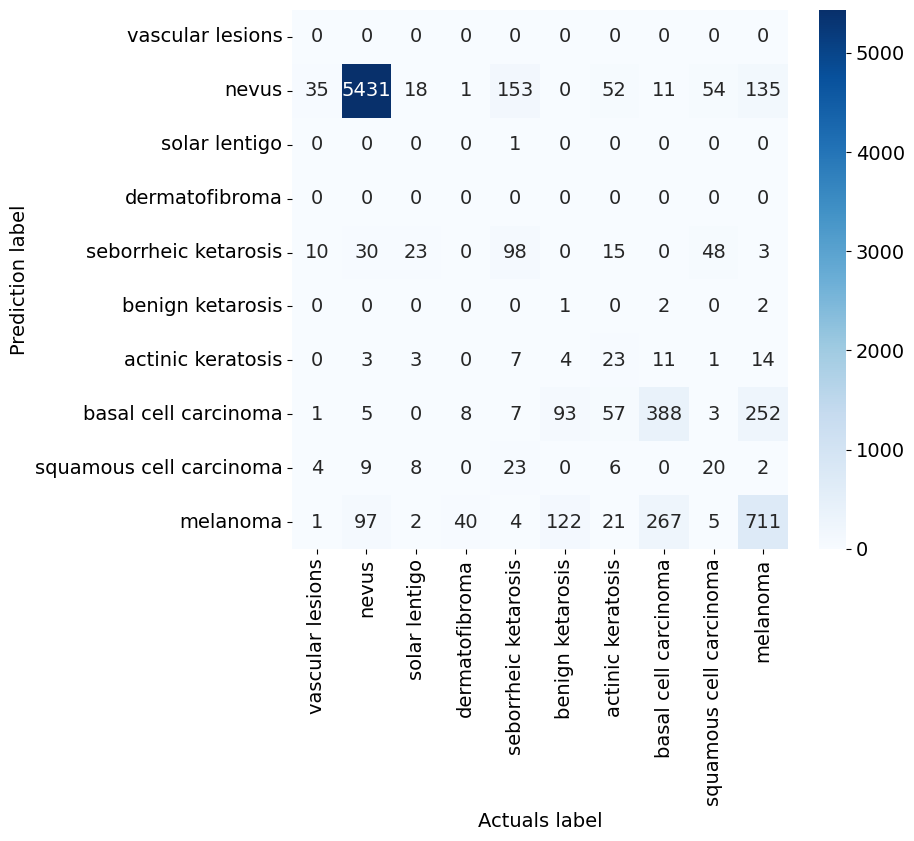

____________________________________________________________
Accuracy score: 79.95
Sensitivity: 0.7995
Specificity: 0.9777
F1: 0.7995
Matthews corrcoef: 0.6010
NPV: 0.9777
PPV: 0.7995
FNR: 0.2005
FPR: 0.0223
____________________________________________________________
Recall micro: 0.7995
Recall macro: 0.2805
Precision micro: 0.7995
Precision macro: 0.3217
F1 score micro: 0.7995
F1 score macro: 0.2837
Jaccard score micro: 0.6660
Jaccard score macro: 0.2127
Specificity macro: 0.9673
Specificity weighted: 0.8736
Specificity none - class vascular lesions (0): 1.0000
Specificity none - class nevus (1): 0.8343
Specificity none - class solar lentigo (2): 0.9999
Specificity none - class dermatofibroma (3): 1.0000
Specificity none - class seborrheic ketarosis (4): 0.9840
Specificity none - class benign ketarosis (5): 0.9995
Specificity none - class actinic keratosis (6): 0.9947
Specificity none - class basal cell carcinoma (7): 0.9444
Specificity none - class squamous cell carcinoma (8): 0.993

C:\Users\Ulyana\anaconda3\envs\NN_3_11_11\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [39]:
actuals = []
predictions = []

test_NN(model_rkd, testloader)

torch.save(actuals, 'model_rkd\\1actuals.pt')
torch.save(predictions, 'model_rkd\\1predictions.pt')

matrix = confusion_matrix(predictions, actuals)
df_matrix = pd.DataFrame(matrix, labels_cat2, labels_cat2)
plt.rcParams['font.size'] = '14'

plt.figure(figsize = (8,7))
sns.heatmap(df_matrix, annot=True, fmt="d", cmap='Blues')
plt.xlabel("Actuals label")
plt.ylabel("Prediction label")
plt.show()

torch.save(matrix, 'model_rkd\\1matrix.pt')

test_metric()